# Performing a Multiple Linear Regression

*Section 5 — Regression, notebook 4 of 6.* Previous: `03_simple_linear_regression`. Next: `05_multivariate_regression`.

**You will learn:**

- how to fit a multiple linear regression with the features selected by LassoLars, and write it as an equation with `rsgispy.regression.regsklearn.get_linear_model_equation`;
- how to plot the predicted against the observed values with `rsgispy.regression.regmetrics.plot_pred_vs_obs`;
- how to turn a fitted linear model into a `band_maths` expression with `get_linear_model_band_maths_exp` and apply it to the image;
- how the choice of features (none, CQV, correlation or LassoLars) changes the accuracy of the model;
- what a jackknife (leave-one-out) assessment is, how to get jackknife confidence intervals of the model coefficients with `perform_jackknife_fit`, and how its accuracy compares with a single test split and a repeated k-fold (`perform_kfold_fit`).

**Before you start:** run `02_feature_selection` first: section 7 reads its `outputs/Forest_Plot_Metrics_CQV_Sel.csv` and `outputs/Forest_Plot_Metrics_Corr_Sel.csv`.

**Data:** `../data/lidar/Forest_Plot_Metrics.csv`, `../data/lidar/Forest_Plot_Metrics_LassoLars_Sel.csv` (the LassoLars selection from notebook 2), `../data/lidar/Forest_ALS_Metrics.tif` and `../data/lidar/Forest_ALS_Valid.tif`.

**Run time:** about 1 minute.

## Overview

In the next step we want to take the analysis a step further where multiple input variables will be considered, in this case we will use the features selected by the LassoLars feature selection processing, previously applied.

# 1. Imports

In [1]:
import os

import pandas
import rsgispy
import rsgispy.regression.regsklearn as rsk
import sklearn.linear_model
import sklearn.model_selection
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imageutils.metadata import get_band_names
from rsgispy.imageutils.stats import pop_img_stats
from rsgispy.mapping.layout import MapPanel, create_map_panels
from rsgispy.regression.regmetrics import calc_reg_metrics, plot_pred_vs_obs

In [2]:
%matplotlib inline

# 2. Read the input plot data 

In [3]:
# Open the CSV file as a Pandas data frame - the df variable.
df = pandas.read_csv("../data/lidar/Forest_Plot_Metrics_LassoLars_Sel.csv", index_col=0)

# Get a list of the columns within the df dataframe
cols = list(df.columns)

# Get the indepedent predictor column names
ind_vars = cols[6:]

# All the files created by this notebook are written to the outputs directory.
out_dir = os.path.join("outputs", "multi_linear_out_imgs")
os.makedirs(out_dir, exist_ok=True)

## 2.1 Summarising the models

`rsgispy.regression.regmetrics.calc_reg_metrics` calculates the accuracy metrics from a table with the observed (reference) and predicted values, including the mean squared error (mse) and the RMSE as a percentage of the mean (nrmse, %RMSE). Here the test values are put into a small DataFrame with an observed (`obs`) and a predicted (`pred`) column.

> **RSGISLib users:** `rsgislib.regression.get_regression_stats(y_test, y_pred, n_vars=1)` returned a list with a dict for each variable; `calc_reg_metrics` returns one dict (with per-target keys for multiple targets) and takes a DataFrame, vector layer or table file.

`rsgispy.regression.regsklearn.get_linear_model_equation` writes a fitted linear model as an equation, and `get_linear_model_coefs` returns its coefficients as a table.

# 3. Fitting a Multiple Linear Regression

Using the scikit-learn library the following scripts fit multiple linear relationships for the three dependent variables. Each model is assessed on the 20% of the plots held back for testing, and `plot_pred_vs_obs` from `rsgispy.regression.regmetrics` plots the predicted against the observed values of those test plots, with the 1:1 line, the least-squares fitted line and the R$^2$, RMSE and bias.

## 3.1 Vol / ha

In [4]:
# Get the selected predictor variables and the 'Vol / ha' dependent variable
# from the dataframe as numpy arrays
x = df[ind_vars].values
y = df["Vol / ha"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
vol_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print(rsk.get_linear_model_equation(vol_mdl, ind_vars, "vol", precision=4))

vol = 385.9782 - 99.0561 * Skew - 228.9510 * CanopyRR - 223.9673 * Oligophotic_Prop - 138.2310 * Euphotic_Prop - 38.1028 * p_mean - 83.1199 * p_kurtosis - 194.0940 * p_variation + 3.4549 * chm_rumple + 10.4328 * chm_ruggedness + 0.0665 * chm_vf + 0.0189 * chm_vl + 0.0342 * wv_midmin


In [5]:
# Predict the values using the model for the test data.
y_pred = vol_mdl.predict(x_test)
regress_vol_stats = calc_reg_metrics(
    pandas.DataFrame({"obs": y_test, "pred": y_pred}), ref_col="obs", pred_col="pred"
)
regress_vol_stats

{'r2': 0.7574009426451654,
 'rmse': 117.19244088915546,
 'mae': 60.990819670818546,
 'bias': -33.87579590308019,
 'explained_variance': 0.7776716509687644,
 'pearson_r': 0.8819248181076775,
 'mse': 13734.068201558199,
 'nrmse': 40.231653778587294,
 'nrmse_range': 15.563405164562479,
 'nbias': -11.629412971574377,
 'n_samples': 34}

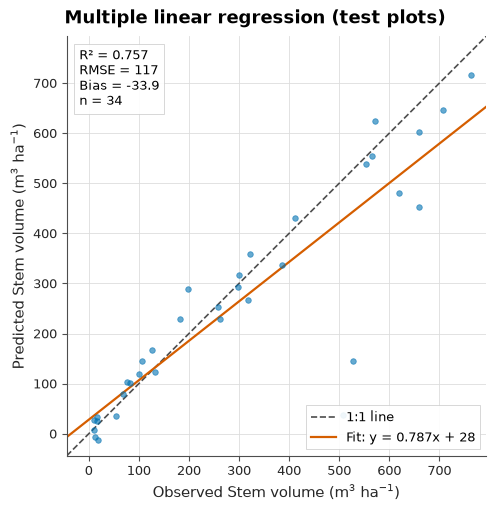

In [6]:
# Plot the predicted against the observed values of the test plots, with the
# 1:1 line and the least-squares line of the predicted on the observed values.
fig, axs = plot_pred_vs_obs(
    pandas.DataFrame({"obs": y_test, "pred": vol_mdl.predict(x_test)}),
    ref_col="obs",
    pred_col="pred",
    target_names=["Stem volume (m$^3$ ha$^{-1}$)"],
    title="Multiple linear regression (test plots)",
)

## 3.2 BA / ha

In [7]:
# Get the selected predictor variables and the 'BA / ha' dependent variable
# from the dataframe as numpy arrays
x = df[ind_vars].values
y = df["BA / ha"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
ba_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print(rsk.get_linear_model_equation(ba_mdl, ind_vars, "ba", precision=4))

ba = 29.8184 - 12.0478 * Skew - 41.6633 * CanopyRR + 19.1700 * Oligophotic_Prop + 9.6014 * Euphotic_Prop - 3.4674 * p_mean - 19.1464 * p_kurtosis + 10.6573 * p_variation + 0.7275 * chm_rumple + 1.3611 * chm_ruggedness + 0.0028 * chm_vf + 0.0026 * chm_vl + 0.0054 * wv_midmin


In [8]:
# Predict the values using the model for the test data.
y_pred = ba_mdl.predict(x_test)
regress_ba_stats = calc_reg_metrics(
    pandas.DataFrame({"obs": y_test, "pred": y_pred}), ref_col="obs", pred_col="pred"
)
regress_ba_stats

{'r2': 0.6201199647741287,
 'rmse': 13.96889544782304,
 'mae': 7.80335847630285,
 'bias': -3.2664592132876815,
 'explained_variance': 0.6408918931018974,
 'pearson_r': 0.8076240101700756,
 'mse': 195.13004003221127,
 'nrmse': 39.31480031670737,
 'nrmse_range': 18.496948421375844,
 'nbias': -9.193296076468787,
 'n_samples': 34}

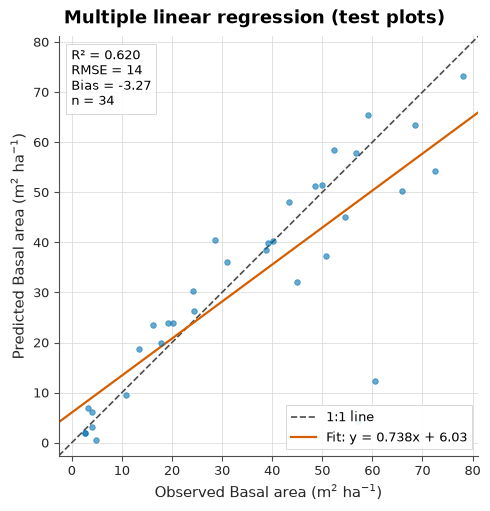

In [9]:
# Plot the predicted against the observed values of the test plots, with the
# 1:1 line and the least-squares line of the predicted on the observed values.
fig, axs = plot_pred_vs_obs(
    pandas.DataFrame({"obs": y_test, "pred": ba_mdl.predict(x_test)}),
    ref_col="obs",
    pred_col="pred",
    target_names=["Basal area (m$^2$ ha$^{-1}$)"],
    title="Multiple linear regression (test plots)",
)

## 3.3 Mean DBH

In [10]:
# Get the selected predictor variables and the 'Mean DBH' dependent variable
# from the dataframe as numpy arrays
x = df[ind_vars].values
y = df["Mean DBH"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
dbh_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print(rsk.get_linear_model_equation(dbh_mdl, ind_vars, "dbh", precision=4))

dbh = 3.0218 - 0.8515 * Skew + 2.4712 * CanopyRR - 11.6747 * Oligophotic_Prop - 2.6500 * Euphotic_Prop + 4.2386 * p_mean + 4.4009 * p_kurtosis + 6.9746 * p_variation - 0.7578 * chm_rumple - 0.4277 * chm_ruggedness - 0.0014 * chm_vf + 0.0042 * chm_vl - 0.0005 * wv_midmin


In [11]:
# Predict the values using the model for the test data.
y_pred = dbh_mdl.predict(x_test)
regress_dbh_stats = calc_reg_metrics(
    pandas.DataFrame({"obs": y_test, "pred": y_pred}), ref_col="obs", pred_col="pred"
)
regress_dbh_stats

{'r2': 0.40113026233151794,
 'rmse': 5.602529592385949,
 'mae': 3.087519185811964,
 'bias': 0.6825771822266158,
 'explained_variance': 0.41001956271292506,
 'pearson_r': 0.7592450849018928,
 'mse': 31.388337833560264,
 'nrmse': 32.231134710849794,
 'nrmse_range': 18.6750986412865,
 'nbias': 3.9268399654323076,
 'n_samples': 34}

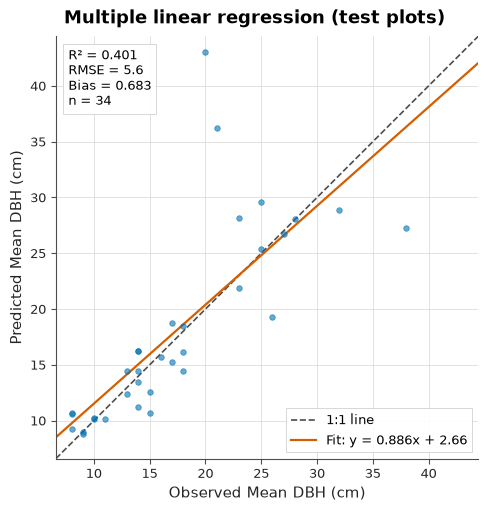

In [12]:
# Plot the predicted against the observed values of the test plots, with the
# 1:1 line and the least-squares line of the predicted on the observed values.
fig, axs = plot_pred_vs_obs(
    pandas.DataFrame({"obs": y_test, "pred": dbh_mdl.predict(x_test)}),
    ref_col="obs",
    pred_col="pred",
    target_names=["Mean DBH (cm)"],
    title="Multiple linear regression (test plots)",
)

# 4. Summarising Results

Within the code above you will see that the data is split to create testing and training datasets, as you would with a classification problem. The testing data can then be used to estimate the accuracy of the model developed, summarised in the table below (created by the next cell):

| Dependant Variable | R2    | MAE  | MSE     | RMSE   | %RMSE  |
| ------------------ | ----- | ---- | ------  | ------ | ------ |
| Vol / ha           | 0.757 | 61.0 | 13734.1 | 117.2  | 40.2 % |
| BA / ha            | 0.620 | 7.8  | 195.1   | 14.0   | 39.3 % |
| Mean DBH           | 0.401 | 3.1  | 31.4    | 5.6    | 32.2 % |

In [13]:
# Summarise the test accuracy of the three models.
summary = pandas.DataFrame(
    {
        "R2": [s["r2"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "MAE": [s["mae"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "MSE": [s["mse"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "RMSE": [s["rmse"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
        "%RMSE": [s["nrmse"] for s in (regress_vol_stats, regress_ba_stats, regress_dbh_stats)],
    },
    index=["Vol / ha", "BA / ha", "Mean DBH"],
)
summary.round(3)

,R2,MAE,MSE,RMSE,%RMSE
Vol / ha,0.757,60.991,13734.068,117.192,40.232
BA / ha,0.620,7.803,195.130,13.969,39.315
Mean DBH,0.401,3.088,31.388,5.603,32.231


# 5. Applying our Model to the Image Data

To apply the models we have just fitted to the image data is pretty straight forward: we just use band maths, ensuring we know which band in the input image is associated with each variable we have used within the relationship (note, check the band descriptions!). For the multiple linear regression the expression can get quite complex, so to avoid errors in transferring the model, `rsgispy.regression.regsklearn.get_linear_model_band_maths_exp` builds the `band_maths` expression directly from the coefficients of the fitted model (in full precision). Each `BandDefn` is named after the predictor variable it holds, and with `valid_msk_name` the model is only applied where the valid mask is 1 (`out_no_data_val`, 0, is written elsewhere).

## 5.1 Create output directory

In [14]:
# The output images are written to out_dir, which was created in section 2.
print(out_dir)

outputs/multi_linear_out_imgs


## 5.2 Define the input image and the bands used by the models

In [15]:
input_img = "../data/lidar/Forest_ALS_Metrics.tif"
vld_msk_img = "../data/lidar/Forest_ALS_Valid.tif"

# The bands of the metrics image are named after the LiDAR metrics, so look up
# the band number (counting from 1) of each metric from its name.
band_idx = {name: i for i, name in enumerate(get_band_names(input_img), start=1)}

# Define the band information, from the input image. This is the same for all three models.
band_info = [BandDefn("vld_msk", vld_msk_img, 1)]
for var in ind_vars:
    band_info.append(BandDefn(var, input_img, band_idx[var]))
    print("{}: band {}".format(var, band_idx[var]))

Skew: band 24
CanopyRR: band 27
Oligophotic_Prop: band 41
Euphotic_Prop: band 42
p_mean: band 43
p_kurtosis: band 46
p_variation: band 47
chm_rumple: band 48
chm_ruggedness: band 49
chm_vf: band 51
chm_vl: band 52
wv_midmin: band 61


## 5.3 Output image format

The outputs are written as GeoTIFF files (`gdalformat="GTIFF"`), which rsgispy creates tiled and DEFLATE-compressed by default.

> **RSGISLib users:** `set_env_vars_lzw_gtiff_outs()` is no longer needed; pass `creation_opts` to `band_maths` to change the GeoTIFF creation options.

## 5.4 Apply Vol / ha 

In [16]:
vol_out_img = os.path.join(out_dir, "Forest_ALS_Volume.tif")

vol_exp = rsk.get_linear_model_band_maths_exp(vol_mdl, ind_vars, valid_msk_name="vld_msk")
print(vol_exp)

# Apply the model to the image and then calculate the image stats and pyramids for visualisation
band_maths(
    vol_out_img, vol_exp, band_info, gdalformat="GTIFF", datatype=rsgispy.TYPE_32FLOAT, no_data_val=0
)
pop_img_stats(vol_out_img, no_data_val=0, calc_pyramids=True)

vld_msk==1?385.97817018179103 + (-99.05607595171487 * Skew) + (-228.95096440294935 * CanopyRR) + (-223.96725036669724 * Oligophotic_Prop) + (-138.23103440805207 * Euphotic_Prop) + (-38.10276801501678 * p_mean) + (-83.11991274057445 * p_kurtosis) + (-194.09395975375128 * p_variation) + (3.4548942395452484 * chm_rumple) + (10.43284533667876 * chm_ruggedness) + (0.06646105930636947 * chm_vf) + (0.018887594336586763 * chm_vl) + (0.034204007274666215 * wv_midmin):0.0


  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

## 5.5 Apply BA / ha

In [17]:
ba_out_img = os.path.join(out_dir, "Forest_ALS_BA.tif")

ba_exp = rsk.get_linear_model_band_maths_exp(ba_mdl, ind_vars, valid_msk_name="vld_msk")
print(ba_exp)

# Apply the model to the image and then calculate the image stats and pyramids for visualisation
band_maths(
    ba_out_img, ba_exp, band_info, gdalformat="GTIFF", datatype=rsgispy.TYPE_32FLOAT, no_data_val=0
)
pop_img_stats(ba_out_img, no_data_val=0, calc_pyramids=True)

vld_msk==1?29.818387883638156 + (-12.04778088506933 * Skew) + (-41.66331232139975 * CanopyRR) + (19.16996368871766 * Oligophotic_Prop) + (9.601370053567221 * Euphotic_Prop) + (-3.4673535547106082 * p_mean) + (-19.14641063761427 * p_kurtosis) + (10.657274010666491 * p_variation) + (0.7274692660372037 * chm_rumple) + (1.3611106556040355 * chm_ruggedness) + (0.002810624799197182 * chm_vf) + (0.0026441046656602756 * chm_vl) + (0.005374143387227867 * wv_midmin):0.0


  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

## 5.6 Apply DBH

In [18]:
dbh_out_img = os.path.join(out_dir, "Forest_ALS_DBH.tif")

dbh_exp = rsk.get_linear_model_band_maths_exp(dbh_mdl, ind_vars, valid_msk_name="vld_msk")
print(dbh_exp)

# Apply the model to the image and then calculate the image stats and pyramids for visualisation
band_maths(
    dbh_out_img, dbh_exp, band_info, gdalformat="GTIFF", datatype=rsgispy.TYPE_32FLOAT, no_data_val=0
)
pop_img_stats(dbh_out_img, no_data_val=0, calc_pyramids=True)

vld_msk==1?3.021797267293552 + (-0.8515089956048942 * Skew) + (2.4712369040970246 * CanopyRR) + (-11.67470336655184 * Oligophotic_Prop) + (-2.6499801771960985 * Euphotic_Prop) + (4.238567039051748 * p_mean) + (4.400919973237513 * p_kurtosis) + (6.974569763756697 * p_variation) + (-0.7578067628867002 * chm_rumple) + (-0.4276780181285492 * chm_ruggedness) + (-0.0013530649916487917 * chm_vf) + (0.0041720743537509266 * chm_vl) + (-0.0004917986044414896 * wv_midmin):0.0


  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/132 [00:00<?, ?it/s]

# 6. Visualise Image Results

As in notebook 3, `rsgispy.mapping.layout.create_map_panels` draws the three maps side by side, each a `'cmap'` panel with a colour bar. Values below `vmin` (here no data, 0) are shown in white.

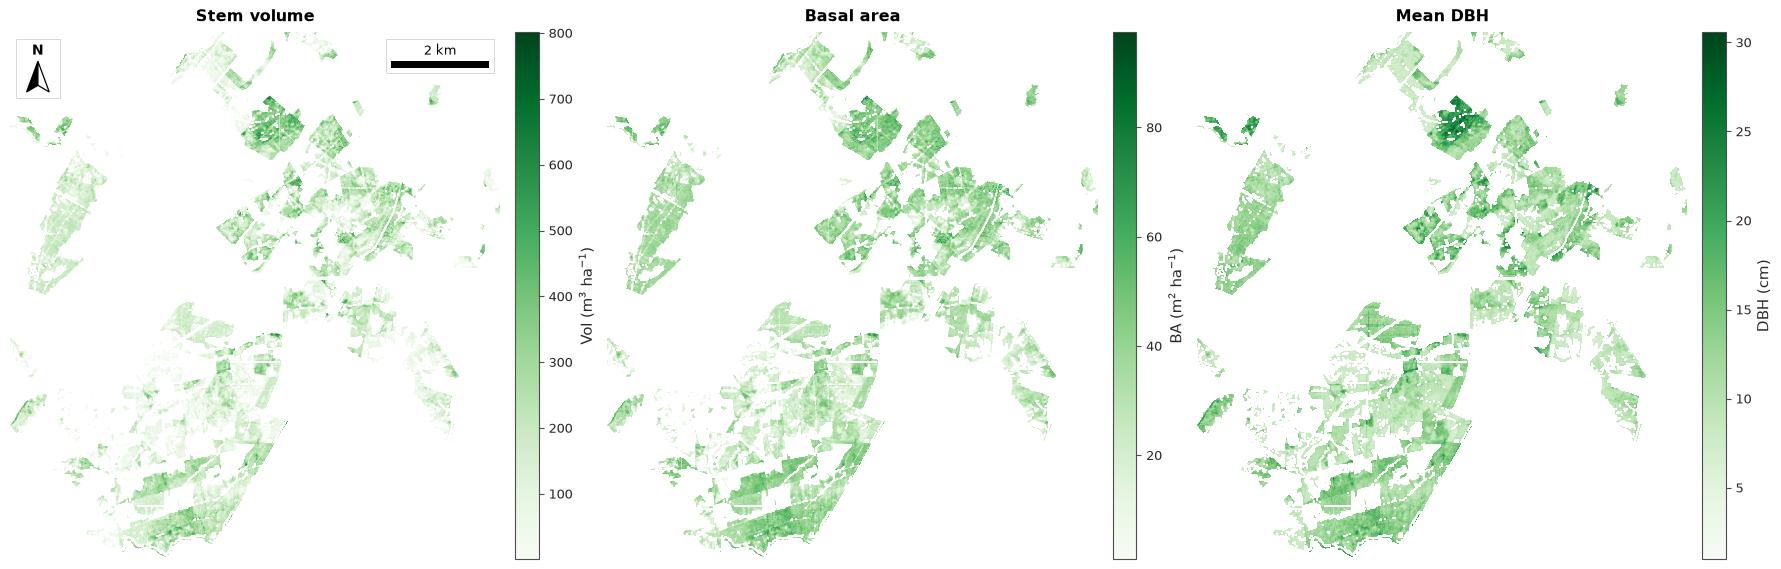

In [19]:
sub_bbox = [291171, 301190, 246680, 257452]

map_info = [
    # (image, title, colour bar label)
    (vol_out_img, "Stem volume", "Vol (m$^3$ ha$^{-1}$)"),
    (ba_out_img, "Basal area", "BA (m$^2$ ha$^{-1}$)"),
    (dbh_out_img, "Mean DBH", "DBH (cm)"),
]
panels = [
    MapPanel(
        "cmap",
        img,
        bands=1,
        title=title,
        cmap_name="Greens",
        vmin=1,
        show_colour_bar=True,
        cbar_label=label,
        map_kw={"vals_under_white": True},
    )
    for img, title, label in map_info
]
fig, axs = create_map_panels(panels, bbox=sub_bbox)

# 7. The Importance of Feature Selection

Earlier, we applied three methods of selecting features based on their importance and we have just seen that by selecting just a single variable we can get a model which in some ways produces a better model that using multiple variables. Try fitting a model for volume and compare the results from the different selected features:


In [20]:
# A dict to collect the test accuracy of each stem volume model.
vol_compare = dict()
vol_compare["LassoLars"] = dict(n_vars=len(cols[6:]), **regress_vol_stats)

## 7.1 Variance-based feature selection

In [21]:
# Open the CSV file as a Pandas data frame - the df variable.
df = pandas.read_csv("outputs/Forest_Plot_Metrics_CQV_Sel.csv", index_col=0)

# Get a list of the columns within the df dataframe
cols = list(df.columns)

# Get the indepedent predictor column names
ind_vars = cols[6:]

# Get the predictor variables and 'Vol / ha' dependent variable
# from the dataframe as numpy arrays
x = df[ind_vars].values
y = df["Vol / ha"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
vol_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print(rsk.get_linear_model_equation(vol_mdl, ind_vars, "vol", precision=4))

# Predict the values of stand volume using the model for the test data.
y_pred = vol_mdl.predict(x_test)
regress_vol_stats = calc_reg_metrics(
    pandas.DataFrame({"obs": y_test, "pred": y_pred}), ref_col="obs", pred_col="pred"
)
vol_compare["CQV"] = dict(n_vars=len(ind_vars), **regress_vol_stats)
regress_vol_stats

vol = 262.0630 + 95.7313 * LPI - 169.4103 * GapFrac - 295.9665 * hMean + 1223.0643 * qhMean + 204.4004 * h25 + 43.6351 * h50 - 250.4010 * h60 - 521.5199 * h70 + 421.3394 * h75 - 153.3604 * h80 + 40.8578 * h90 - 111.7443 * h95 - 68.4847 * h99 - 6.3553 * hmax + 216.9389 * IQR - 295.9665 * L_mean + 218.4255 * L_scale + 0.0224 * Closed_Vol + 0.0468 * Open_Vol + 0.1447 * Oligophotic_Vol + 0.0137 * cvm_filled_vol + 429.7791 * Closed_Prop - 210.7088 * Open_Prop - 392.1273 * Oligophotic_Prop + 22.5436 * p_mean - 97.0880 * p_scale - 51.7467 * p_skewness + 53.8885 * p_kurtosis + 7.1548 * chm_rumple + 15.4292 * chm_ruggedness - 4.9611 * chm_roughness - 0.6237 * chm_vf + 0.6299 * chm_vl + 0.6211 * chm_vd + 56.5574 * wv_auc - 31.3446 * wv_mid - 14.5191 * wv_width + 0.0006 * wv_midmax - 94.0391 * h25f + 99.0187 * h50f + 76.4738 * h60f - 489.3008 * h70f + 807.9786 * h75f - 736.1328 * h80f + 3.9653 * h85f - 2.2933 * h90f - 39.6959 * h95f + 23.4710 * h99f + 184.1243 * L_mean_f - 3.3141 * L_scale_f


{'r2': 0.8956406415371432,
 'rmse': 76.86360431050605,
 'mae': 52.437958154648975,
 'bias': -6.80026852921294,
 'explained_variance': 0.8964574910121887,
 'pearson_r': 0.9476491435400388,
 'mse': 5908.013667602044,
 'nrmse': 26.386940090440284,
 'nrmse_range': 10.207649974834801,
 'nbias': -2.3345025241643773,
 'n_samples': 34}

## 7.2 Correlation-based feature selection

In [22]:
# Open the CSV file as a Pandas data frame - the df variable.
df = pandas.read_csv("outputs/Forest_Plot_Metrics_Corr_Sel.csv", index_col=0)

# Get a list of the columns within the df dataframe
cols = list(df.columns)

# Get the indepedent predictor column names
ind_vars = cols[6:]

# Get the predictor variables and 'Vol / ha' dependent variable
# from the dataframe as numpy arrays
x = df[ind_vars].values
y = df["Vol / ha"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
vol_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print(rsk.get_linear_model_equation(vol_mdl, ind_vars, "vol", precision=4))

# Predict the values of stand volume using the model for the test data.
y_pred = vol_mdl.predict(x_test)
regress_vol_stats = calc_reg_metrics(
    pandas.DataFrame({"obs": y_test, "pred": y_pred}), ref_col="obs", pred_col="pred"
)
vol_compare["Correlation"] = dict(n_vars=len(ind_vars), **regress_vol_stats)
regress_vol_stats

vol = 104.5303 + 0.0128 * wv_minmax - 231.0955 * VDR + 2.3705 * wv_peaks + 0.0679 * chm_vf - 0.0027 * Closed_Vol - 0.0045 * N_Returns


{'r2': 0.8509906674980929,
 'rmse': 91.84632419314104,
 'mae': 56.130783338129206,
 'bias': -25.749101951190625,
 'explained_variance': 0.8627022095709889,
 'pearson_r': 0.9299201628455247,
 'mse': 8435.747267791567,
 'nrmse': 31.530442473412716,
 'nrmse_range': 12.197387011041307,
 'nbias': -8.839554385505666,
 'n_samples': 34}

## 7.3 All Variables (i.e., not feature selection)

In [23]:
# Open the CSV file as a Pandas data frame - the df variable.
df = pandas.read_csv("../data/lidar/Forest_Plot_Metrics.csv")

# Get a list of the columns within the df dataframe
cols = list(df.columns)

# Get the indepedent predictor column names
ind_vars = cols[6:]

# Get the predictor variables and 'Vol / ha' dependent variable
# from the dataframe as numpy arrays
x = df[ind_vars].values
y = df["Vol / ha"].values

# Randomly sample the input data to create training and testing (20% sample) datasets
# so we have an independent dataset to test the quality of the relationship
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)

# Create a LinearRegression object
lm = sklearn.linear_model.LinearRegression()

# Fit the model using the training data
vol_mdl = lm.fit(x_train, y_train)

# Print the equation of the model
print(rsk.get_linear_model_equation(vol_mdl, ind_vars, "vol", precision=4))

# Predict the values of stand volume using the model for the test data.
y_pred = vol_mdl.predict(x_test)
regress_vol_stats = calc_reg_metrics(
    pandas.DataFrame({"obs": y_test, "pred": y_pred}), ref_col="obs", pred_col="pred"
)
vol_compare["All variables"] = dict(n_vars=len(ind_vars), **regress_vol_stats)
regress_vol_stats

vol = -184.1337 + 0.0121 * N_Pulses - 0.0091 * N_Returns + 103.4600 * First_Return - 103.4600 * Multi_Return + 9.8323 * LPI - 72.0427 * CDensity + 6.9456 * FCI - 0.6830 * LCI + 72.1282 * GapFrac - 2.2954 * VCC - 162.9346 * hMean + 740.6108 * qhMean + 242.5541 * h25 - 0.4537 * h50 - 158.8915 * h60 - 361.4361 * h70 + 461.3516 * h75 - 300.6911 * h80 + 8.0099 * h90 - 133.5515 * h95 + 31.0186 * h99 + 32.7609 * hmax + 218.7974 * IQR + 19.5945 * Skew - 22.0297 * Kurtosis + 5.2737 * VDR - 167.7092 * CanopyRR - 162.9346 * L_mean + 192.7105 * L_scale - 108.9346 * L_skewness - 111.3991 * L_kurtosis + 340.5242 * L_variation - 0.0531 * Closed_Vol - 0.0504 * Open_Vol + 0.0542 * Oligophotic_Vol - 0.0659 * Euphotic_Vol - 0.0117 * cvm_filled_vol - 110.6611 * cvm_filled_prop - 26.6765 * Closed_Prop + 130.1236 * Open_Prop - 85.7232 * Oligophotic_Prop - 24.9379 * Euphotic_Prop + 117.0109 * p_mean - 269.5004 * p_scale - 30.0767 * p_skewness + 194.7526 * p_kurtosis + 8.3100 * p_variation + 5.3913 * chm_rump

{'r2': 0.8890526554224372,
 'rmse': 79.25259683616532,
 'mae': 57.564089835351965,
 'bias': 3.835415672640763,
 'explained_variance': 0.8893125006749425,
 'pearson_r': 0.9486890881894603,
 'mse': 6280.974105275763,
 'nrmse': 27.207070804014748,
 'nrmse_range': 10.52491325845489,
 'nbias': 1.3166814708177093,
 'n_samples': 34}

## 7.4 Simple linear regression

For comparison, the simple linear regression with `chm_vf` from notebook 3, fitted to the same training samples:

In [24]:
x = df[["chm_vf"]].values
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(
    x, y, test_size=0.2, random_state=0
)
simple_mdl = sklearn.linear_model.LinearRegression().fit(x_train, y_train)
simple_stats = calc_reg_metrics(
    pandas.DataFrame({"obs": y_test, "pred": simple_mdl.predict(x_test)}), ref_col="obs", pred_col="pred"
)
vol_compare["Simple (chm_vf)"] = dict(n_vars=1, **simple_stats)

# Summarise the stem volume models, sorted by the RMSE.
vol_compare_df = pandas.DataFrame(vol_compare).T[["n_vars", "r2", "rmse", "nrmse", "mae", "bias"]]
vol_compare_df.astype(float).round(3).sort_values("rmse")

,n_vars,r2,rmse,nrmse,mae,bias
Simple (chm_vf),1.0,0.919,67.857,23.295,46.837,-19.773
CQV,50.0,0.896,76.864,26.387,52.438,-6.800
All variables,78.0,0.889,79.253,27.207,57.564,3.835
Correlation,6.0,0.851,91.846,31.530,56.131,-25.749
LassoLars,12.0,0.757,117.192,40.232,60.991,-33.876


## 7.5 Summary

So, what does this table show us? The RMSE shows us that the single parameter simple regression has the least error, followed by the CQV selection, all the variables, the correlation selection and then LassoLars, which has actually performed worse than applying a regression with no feature selection. From these metrics we would probably choose the single parameter model (section 8 checks this with every plot tested, rather than one split of 34 test plots). Using more features does not by itself give a better model: the models with 50 and 78 predictors fit the training data closely but do no better on the test data than one predictor, and their coefficients (printed above) are large and of opposite sign for correlated predictors, a sign of multicollinearity. The other thing to note here is that while R2 provides us some useful information on the fit of the model it is not a useful metric for comparing the quality of individual models.

# 8. Jackknife Assessment of the Linear Models

In sections 3 and 7 each model was assessed on one random split of the plots, with 34 test plots. With so few plots, the accuracy depends a lot on which plots happen to be in the test set, and the other 132 plots are never tested. Resampling methods test every plot:

* a **k-fold cross-validation** (used in notebooks 5 and 6) splits the plots at random into k folds (e.g., 5); each fold is predicted by a model fitted to the other folds, and the whole process is repeated with different random splits;
* a **jackknife** (Quenouille, 1949; Tukey, 1958), also called leave-one-out cross-validation, fits the model n times (once for each of the n plots), each time leaving out one plot, and predicts the plot that was left out. The n out-of-sample predictions are pooled to give one set of accuracy metrics. There is no random split, so the result is the same every time, but the model is fitted n times (166 here, which is quick for a linear model).

As each of the n jackknife models is fitted without one plot, the jackknife also shows how much each **coefficient** of the model changes when a plot is removed. From the n estimates of a coefficient we get its jackknife standard error, its bias and a 95% confidence interval (Efron and Tibshirani, 1993). A coefficient whose interval includes zero is not well determined by the data: we cannot even be sure of its sign.

`rsgispy.regression.regsklearn.perform_jackknife_fit` does all of this for any scikit-learn regressor (with `groups`, one group of samples, e.g. the plots of one forest, is left out at a time). It returns a dict with the pooled leave-one-out `metrics`, the out-of-sample predictions (`residuals`), the `influence` of each plot and, for a linear model, the coefficient statistics (`coef_stats`), each keyed by the response variable. With `out_dir` they are also written to CSV files.

> **RSGISLib users:** RSGISLib did not have a jackknife (leave-one-out) assessment of a regressor. `rsgispy.regression.regfeatures.calc_jackknife_feature_importance` is different: it leaves out features, not samples.

## 8.1 Jackknife of the LassoLars multiple linear regression

The model is fitted to all three response variables at once; a scikit-learn `LinearRegression` with several targets is the same as a separate model for each.

In [25]:
# Read the LassoLars selected features again (section 7 changed df and ind_vars).
df = pandas.read_csv("../data/lidar/Forest_Plot_Metrics_LassoLars_Sel.csv", index_col=0)
ind_vars = list(df.columns)[6:]
resp_vars = ["Vol / ha", "BA / ha", "Mean DBH"]

jk_dir = os.path.join("outputs", "multi_linear_jackknife")
jk = rsk.perform_jackknife_fit(
    sklearn.linear_model.LinearRegression(),
    df[ind_vars],
    df[resp_vars],
    out_dir=jk_dir,
    out_prefix="jk_lassolars",
)
sorted(os.listdir(jk_dir))

  0%|          | 0/166 [00:00<?, ?it/s]

['jk_lassolars_coef_stats_ba_ha.csv',
 'jk_lassolars_coef_stats_mean_dbh.csv',
 'jk_lassolars_coef_stats_vol_ha.csv',
 'jk_lassolars_influence_ba_ha.csv',
 'jk_lassolars_influence_mean_dbh.csv',
 'jk_lassolars_influence_vol_ha.csv',
 'jk_lassolars_metrics_ba_ha.csv',
 'jk_lassolars_metrics_mean_dbh.csv',
 'jk_lassolars_metrics_vol_ha.csv',
 'jk_lassolars_residuals_ba_ha.csv',
 'jk_lassolars_residuals_mean_dbh.csv',
 'jk_lassolars_residuals_vol_ha.csv']

## 8.2 Jackknife coefficient intervals

The coefficient statistics of the stem volume model: the `estimate` from all the plots, the jackknife `bias` and standard error (`std_err`), and the 95% confidence interval (`ci_lower`, `ci_upper`) around the bias-corrected estimate:

In [26]:
vol_coefs = jk["coef_stats"]["Vol / ha"][["estimate", "bias", "std_err", "ci_lower", "ci_upper"]].copy()
vol_coefs["includes_zero"] = (vol_coefs["ci_lower"] < 0) & (vol_coefs["ci_upper"] > 0)
vol_coefs.round(4)

,estimate,bias,std_err,ci_lower,ci_upper,includes_zero
coef,,,,,,
intercept,240.1265,9.6586,152.1918,-70.0265,530.9623,True
Skew,-41.5354,-4.7330,34.9505,-105.8103,32.2054,True
CanopyRR,3.3385,-23.6995,172.4018,-313.3599,367.4359,True
Oligophotic_Prop,-117.3058,-7.4438,135.2116,-376.8300,157.1060,True
Euphotic_Prop,-202.8988,7.2587,71.9702,-352.2587,-68.0562,False
p_mean,12.2686,-4.1298,14.9181,-13.0566,45.8534,True
p_kurtosis,129.9787,-36.5027,199.1460,-226.7216,559.6843,True
p_variation,-390.1053,24.1082,138.0946,-686.8738,-141.5532,False
chm_rumple,3.9975,0.2519,7.5286,-11.1192,18.6104,True


In [27]:
# The number of the 12 predictor coefficients (not the intercept) whose
# 95% interval includes zero, for each response variable.
for resp_var in resp_vars:
    coefs = jk["coef_stats"][resp_var].drop(index="intercept")
    n_zero = ((coefs["ci_lower"] < 0) & (coefs["ci_upper"] > 0)).sum()
    print("{}: {} of {} coefficient intervals include zero".format(resp_var, n_zero, len(coefs)))

Vol / ha: 9 of 12 coefficient intervals include zero
BA / ha: 12 of 12 coefficient intervals include zero
Mean DBH: 9 of 12 coefficient intervals include zero


Only 3 of the 12 predictor coefficients of the stem volume model (`Euphotic_Prop`, `p_variation` and `chm_vl`) have 95% intervals that exclude zero, and none of the basal area coefficients do, although the models predict the plots well (section 8.3). This is the multicollinearity we found in notebook 1: the predictors are correlated with each other, so the data cannot separate their effects, and leaving out a single plot can change a coefficient a lot (e.g., the `CanopyRR` coefficient of the stem volume model is 3.3 with a standard error of 172). The jackknife biases are small compared with the standard errors. The predictions can still be good, as the correlated coefficients change together, but the individual coefficients should not be interpreted (e.g., 'stem volume decreases with `p_variation`'), and the model may give poor values for pixels whose combination of predictor values is unlike those of the plots.

In [28]:
# The jackknife of the simple linear regression of stem volume on chm_vf (notebook 3).
jk_simple = rsk.perform_jackknife_fit(
    sklearn.linear_model.LinearRegression(),
    df[["chm_vf"]],
    df["Vol / ha"],
    out_dir=jk_dir,
    out_prefix="jk_simple",
)
jk_simple["coef_stats"]["Vol / ha"][["estimate", "bias", "std_err", "ci_lower", "ci_upper"]].round(4)

  0%|          | 0/166 [00:00<?, ?it/s]

,estimate,bias,std_err,ci_lower,ci_upper
coef,,,,,
intercept,-61.6549,0.1690,8.6549,-78.9127,-44.7352
chm_vf,0.0735,-0.0001,0.0025,0.0687,0.0785


By contrast, the coefficients of the simple linear regression of stem volume on `chm_vf` are well determined: the slope is 0.0735 with a standard error of 0.0025 (95% interval 0.0687 to 0.0785), and the jackknife bias is negligible. (These coefficients are a little different from those in notebook 3, which were fitted to the 132 training plots only; the notebook 3 slope, 0.0719, is within the interval.)

## 8.3 Comparing the jackknife with the test split and a k-fold

For comparison, the same models are assessed with a repeated k-fold cross-validation (5 folds repeated 20 times, as in notebooks 5 and 6) with `perform_kfold_fit`, and `summarise_kfold_metrics` gives the mean, median, standard deviation and the 5th and 95th percentiles of each metric over the 100 folds:

In [29]:
kf_metrics, kf_residuals = rsk.perform_kfold_fit(
    sklearn.linear_model.LinearRegression(),
    df[ind_vars],
    df[resp_vars],
    n_splits=5,
    n_repeats=20,
    rnd_seed=0,
    out_dir=jk_dir,
    out_prefix="kfold_lassolars",
)
kf_summary = rsk.summarise_kfold_metrics(kf_metrics)

kf_simple_metrics, _ = rsk.perform_kfold_fit(
    sklearn.linear_model.LinearRegression(),
    df[["chm_vf"]],
    df["Vol / ha"],
    n_splits=5,
    n_repeats=20,
    rnd_seed=0,
)
kf_simple_summary = rsk.summarise_kfold_metrics(kf_simple_metrics)
kf_summary.loc["Vol / ha"].round(3)

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

,mean,median,std,p05,p95
metric,,,,,
r2,0.887,0.901,0.060,0.805,0.933
rmse,64.601,61.858,14.932,49.919,84.670
mae,45.800,43.884,8.271,36.129,62.025
bias,-0.775,1.771,12.525,-21.252,16.590
explained_variance,0.890,0.904,0.058,0.806,0.936
pearson_r,0.947,0.953,0.028,0.906,0.971
mse,4394.043,3826.471,2417.763,2491.984,7172.817
nrmse,23.376,22.767,4.854,17.662,28.963
nrmse_range,8.388,7.964,2.154,6.411,11.196


In [30]:
# The %RMSE (nrmse) and bias of each model from the single test split
# (sections 3 and 7.4), the jackknife and the k-fold.
split_stats = {
    "Vol / ha": vol_compare["LassoLars"],
    "BA / ha": regress_ba_stats,
    "Mean DBH": regress_dbh_stats,
}
rows = dict()
for resp_var in resp_vars:
    rows[(resp_var, "LassoLars")] = (split_stats[resp_var], jk["metrics"][resp_var], kf_summary.loc[resp_var])
rows[("Vol / ha", "Simple (chm_vf)")] = (
    vol_compare["Simple (chm_vf)"],
    jk_simple["metrics"]["Vol / ha"],
    kf_simple_summary.loc["Vol / ha"],
)
compare_df = pandas.DataFrame(
    {
        key: {
            "split_nrmse": split["nrmse"],
            "jk_nrmse": jack["nrmse"],
            "kfold_nrmse_median": kfold.loc["nrmse", "median"],
            "kfold_nrmse_p05": kfold.loc["nrmse", "p05"],
            "kfold_nrmse_p95": kfold.loc["nrmse", "p95"],
            "split_bias": split["bias"],
            "jk_bias": jack["bias"],
            "kfold_bias_mean": kfold.loc["bias", "mean"],
        }
        for key, (split, jack, kfold) in rows.items()
    }
).T
compare_df.to_csv(os.path.join(jk_dir, "split_jackknife_kfold_compare.csv"))
compare_df.round(2)

,,split_nrmse,jk_nrmse,kfold_nrmse_median,kfold_nrmse_p05,kfold_nrmse_p95,split_bias,jk_bias,kfold_bias_mean
Vol / ha,LassoLars,40.23,22.94,22.77,17.66,28.96,-33.88,-0.99,-0.77
BA / ha,LassoLars,39.31,21.56,21.65,17.30,26.35,-3.27,-0.12,-0.11
Mean DBH,LassoLars,32.23,18.62,19.04,13.66,23.72,0.68,0.04,0.05
Vol / ha,Simple (chm_vf),23.30,24.21,24.03,18.33,28.98,-19.77,-0.10,-0.13


What does this table show us?

* The jackknife %RMSE is close to the median %RMSE of the k-fold folds for every model (e.g., 22.9 % and 22.8 % for stem volume), and the jackknife and mean k-fold biases are all close to zero. Both methods test every plot, so they agree.
* The single test split gave much larger errors for the LassoLars models (40.2 % for stem volume), above the 95th percentile of the k-fold folds (29.0 %). Its 34 test plots happen to include two of the three plots that the jackknife predicts worst (plots 60 and 93, see section 8.4): one split of a small sample can be unlucky (or lucky).
* The k-fold also shows the spread of the accuracy: a fold of 33-34 plots can have a %RMSE anywhere between about 18 % and 29 % for stem volume (the 5th and 95th percentiles). The pooled jackknife metrics are a single value without a spread; for the jackknife, the spread is in the coefficients (section 8.2).
* With every plot tested, the ranking of section 7 changes: the LassoLars model (jackknife 22.9 %) is slightly more accurate than the simple `chm_vf` model (24.2 %), rather than much worse. The difference is small compared with the spread between the folds, though, and the simple model has well-determined coefficients, so it might still be preferred.

The jackknife needs one fit per sample, so it suits small samples such as these 166 plots with a model that is quick to fit. For large samples or slow models, such as the Extra Trees regressor in notebook 5, the repeated k-fold is cheaper and also gives the spread of the metrics.

## 8.4 Jackknife predictions and influential plots

The pooled leave-one-out predictions can be plotted like any other predictions:

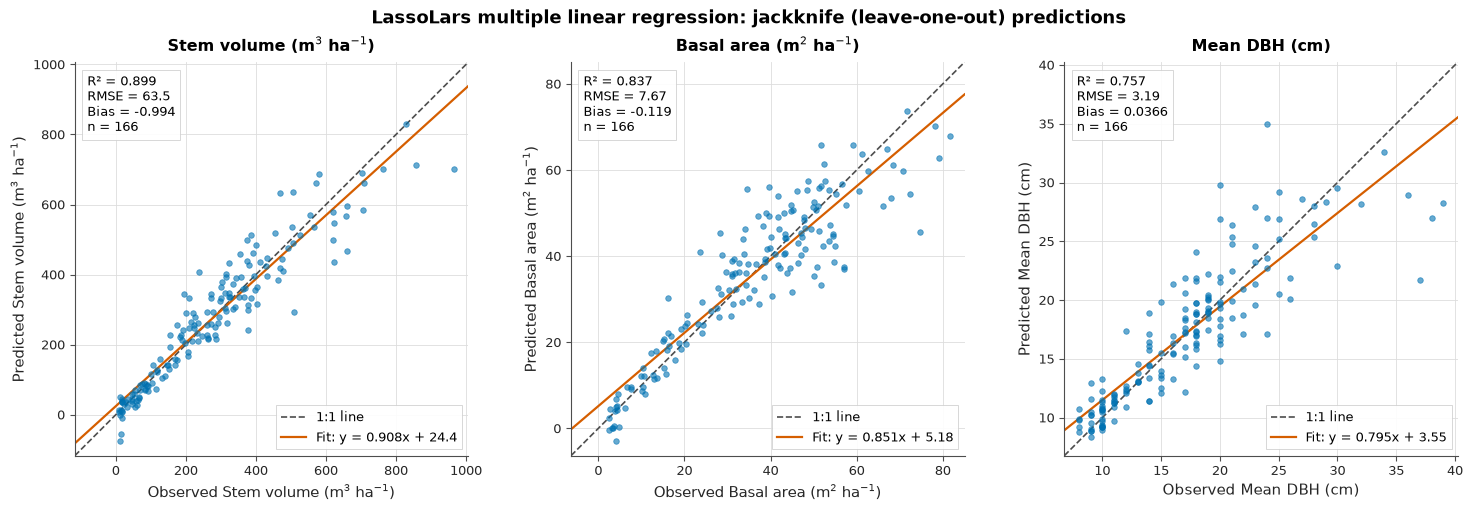

In [31]:
# One observed and one predicted column per response variable.
jk_pred_df = pandas.DataFrame()
for i, resp_var in enumerate(resp_vars):
    jk_pred_df["obs_{}".format(i)] = jk["residuals"][resp_var]["y_true"]
    jk_pred_df["pred_{}".format(i)] = jk["residuals"][resp_var]["y_pred"]

fig, axs = plot_pred_vs_obs(
    jk_pred_df,
    ref_cols=["obs_{}".format(i) for i in range(len(resp_vars))],
    pred_cols=["pred_{}".format(i) for i in range(len(resp_vars))],
    target_names=["Stem volume (m$^3$ ha$^{-1}$)", "Basal area (m$^2$ ha$^{-1}$)", "Mean DBH (cm)"],
    title="LassoLars multiple linear regression: jackknife (leave-one-out) predictions",
)

The `influence` table shows which plots change the model the most when they are left out (`pred_shift_rmse`, the RMS change of the predictions of all the plots) and which are predicted worst (`delta_cv_rmse`, the change of the leave-one-out RMSE without the plot; a large negative value is a plot that is predicted badly). These are the plots to check first for errors in the field data or the LiDAR metrics:

In [32]:
jk["influence"]["Vol / ha"].nlargest(5, "pred_shift_rmse").round(2)

,sample_idx,y_true,y_pred,delta_cv_rmse,delta_fit_rmse,pred_shift_rmse
60,60,508.0,293.29,-2.04,-0.63,10.96
104,104,469.0,632.64,-1.09,-0.32,7.19
86,86,624.0,435.53,-1.52,-0.34,6.92
20,20,705.0,585.02,-0.50,-0.20,6.62
68,68,858.0,712.71,-0.82,-0.22,5.72


Plot 60 changes the stem volume model the most when it is left out (`pred_shift_rmse` of 11.0 m$^3$ ha$^{-1}$), and it is also predicted badly (508 m$^3$ ha$^{-1}$ observed, 293 m$^3$ ha$^{-1}$ predicted when it is left out), so it would be worth checking. The influence tables of the three response variables were written to `outputs/multi_linear_jackknife`, with the other jackknife and k-fold outputs.

## References

* Efron, B. and Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall, New York (chapter 11, the jackknife).
* Quenouille, M. H. (1949). Approximate tests of correlation in time-series. *Journal of the Royal Statistical Society, Series B*, 11(1), 68-84.
* Tukey, J. W. (1958). Bias and confidence in not-quite large samples (abstract). *Annals of Mathematical Statistics*, 29(2), 614.